<a href="https://colab.research.google.com/github/Nishijannat/FederatedLearning/blob/main/Liver_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
#loads os module
#interacting with the operating system of the device
#necessary to create folder and read environmental variables


import os

In [8]:
#


import sys

In [9]:
#loads numpy package
#does fast maths on arrays of number
#np is the name as which the package is installed


import numpy as np

#importing warnings package to print warning messages
import warnings



In [10]:
#pandas package
#handles datafreames/spreadsheets
import pandas as pd

#loads plotting library
import matplotlib

#Aggs draws plot into image files without opening new window
matplotlib.use("Agg")

#plotting function from matplotlib
import matplotlib.pyplot as plt


## Data Preprocessing & Feature Transformation

```
SimpleImputer
```
1. Handling Missing Values:
  As this datasets have some missing values (Nan/null) due to measurement erros or any kind of failure in surveys, before putting them into algorithm like logistic regression. As its not logistic regression's work to replace m issing values.

    Mechanism:
      Mean: If tghe features are normally distributed and continuous features. Sensitive to extreme outliers.
      Median: Robust to outliers and skewed distribution.
      Most Frequent Mode: Suitable for catergorial or discrete variables.
      Constant: Replaces missing entries with an explicit arbitary value


```
StandardScaler
```
2. Feature Scaling:
   Feautres with large magnitudes can dominate the optimization objective in gradient descent or skew distance calculation. Need to scale them for proper evaluation.
   Mechanism:
   Standard scaling transforms each feature to have a mean of 0 and a standard deviation of 1.

   𝖹 = (𝓧-𝝻)÷δ
where 𝝻 is the empirical feature mean and δ is the standard deviation.


```
FunctionTransformer
```
3. Custin Transformations:
   Some features follow exponential distribution. We need to applymathematical transformations like logarithmic scale, square root, power transforms to stabilzie the variances and make distribution closer to normal
   Mechanism:
   This function wraps stteless python functions into scikit-learn [transformers so they can be intergated safely inside pipelines without data leakage.

## Supervised Classification Algorithms

```
Logistic Regression
```

1. Logistic Regression:
This is a foundational linear model for binary classification.  This models the log-odds of the positive class as a linear combination of input features.
There are some advantages of this model - fast to train, highly interpretable as coefficents represent directional feature impacts



  𝑃(𝐲 = 1 | 𝓧) = 𝛅(𝑤ᵀ𝓧 + 𝐛)


```
RandomForestClassifier
```

2. Random Forest Classifier:
An ensemble method based on the principle of bootstrap aggregating. It builds a forest of B independent decision trees


*   Bootstrap Sampling: Each tree is trained on a sample drawn with replacement from the training set
*   Feature Subsampling: At each split, only a random subset of features is considered
*   Aggregation: Predictions are averaged accross all trees or decided via majority vote.

Variance Reduction: While an individual deep decision tree has low bias but high variance - data overfits.








**Raw Data**
--->
Preproecessing
(StandardScalar, SimpleImputer, FunctionTransformer)
--->>
Validation & Tuning
(RepeatedStratifiedKFold, GrdidSearchCV, cross_validate)
---->>
Probability Calibration
(CalibratedClassifierCV, calibration_curve)
---->>
Evaluration (roc_auc_score, brier_score_loss)
---->>Interpretation (permutation importance)
**bold text**


In [11]:
#scikit-learn, widely used machine learning python lybrary
#built-in machine learning code



#starting with and loading a fresh untrained model with same settings
from sklearn.base import clone

#wraps a model
#corrects its porbabilities
#ccomputes points of the reliability plot
from sklearn.calibration import CalibratedClassifierCV , calibration_curve

#tree-based classifiers
#HistGradientBoodtingClassifier: Fast historgram-based GBDT
#Hnadles native missing values and large datasetsw well
#Random Forest classsifier: Ensemble of decdision trees trained on bootstrap samples with random feature subsets
from sklearn.ensemble import HistGradientBoostingClassifier , RandomForestClassifier

#fils missing values, here median is used
from sklearn.impute import SimpleImputer

#measures hoiw much the score drops when one feature is shuffled
#if large drop,, the feature is important
from sklearn.inspection import permutation_importance

#standard regularised logistic regression for linear classification
from sklearn.linear_model import LogisticRegression

#measures how good the probabilities are
#measures ranking ability
#evaluation metrics
from sklearn.metrics import brier_score_loss , roc_auc_score


# 8. Model Selection & Cross-Validation
# GridSearchCV: Exhaustive search over specified parameter values evaluated by cross-validation.
# RepeatedStratifiedKFold: Repeats stratified K-fold cross-validation n times with different random splits.
# StratifiedGroupKFold: Preserves class balance while ensuring groups/clusters do not span across train/val splits.
# cross_val_predict: Generates out-of-fold predictions.
# cross_validate: Evaluates metric(s) by cross-validation and records fit/score times.
from sklearn. model_selection import (GridSearchCV ,
                                      RepeatedStratifiedKFold ,
                                      StratifiedGroupKFold ,
                                      cross_val_predict,
                                      cross_validate)

#Converts arbitrary Python callables into stateless pipline transformer (np.log1p)
#Standardscaler: Standerdizes features by removuing the mean and scaling to unit variances
from sklearn.preprocessing import FunctionTransformer , StandardScaler

In [12]:
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.pipeline import Pipeline

In [13]:
!pip install imblearn

In [14]:
warnings.filterwarnings("ignore")

In [15]:
#A fixed number that seeds all randomness process -shuffling, sampling
#


SEED = 42

In [21]:
CSV = "/content/indian_liver_patient.csv"

In [22]:
REPEATS = int(os.environ.get("REPEATS", 5))
OUT = os.environ.get("OUT", "outputs")
os.makedirs(OUT, exist_ok=True)


In [23]:
df = pd.read_csv(CSV)
df = df.rename(columns={
    "Alkaline_Phosphotase": "ALP",
    "Alamine_Aminotransferase": "ALT",
    "Aspartate_Aminotransferase": "AST",
    "Total_Protiens": "Total_Proteins",
})

In [24]:
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)  # ILPD contains duplicate rows
print(f"Rows: {n_raw} -> {len(df)} after dropping exact duplicates")

Rows: 583 -> 570 after dropping exact duplicates


In [25]:

df["Gender"] = (df["Gender"].str.strip().str.lower() == "male").astype(int)  # 1 = male
y = (df["Dataset"] == 1).astype(int)  # 1 = liver patient
X = df.drop(columns="Dataset")
print("Missing values:\n", X.isna().sum()[X.isna().sum() > 0])
print("Class balance (1 = patient):\n", y.value_counts(normalize=True).round(3))

Missing values:
 Albumin_and_Globulin_Ratio    4
dtype: int64
Class balance (1 = patient):
 Dataset
1    0.712
0    0.288
Name: proportion, dtype: float64


In [26]:

# ----------------------------------------------- 2. CLINICAL FEATURE ENGINEERING
LOG_COLS = ["Total_Bilirubin", "Direct_Bilirubin", "ALP", "ALT", "AST"]


def fe(X, engineered=True):
    """Stateless transform (no fitted parameters), so it cannot leak."""
    X = X.copy()
    if engineered:
        X["De_Ritis"] = X["AST"] / (X["ALT"] + 1e-3)  # AST/ALT
        X["Direct_Total_Bili"] = X["Direct_Bilirubin"] / (X["Total_Bilirubin"] + 1e-3)
        X["Globulin"] = X["Total_Proteins"] - X["Albumin"]
        X["De_Ritis"] = np.log1p(X["De_Ritis"])
    for c in LOG_COLS:
        X[c] = np.log1p(X[c])  # right-skewed enzymes/bilirubin
    return X


def make_pipe(clf, engineered=True, sampler=None):
    steps = [
        ("fe", FunctionTransformer(fe, kw_args={"engineered": engineered})),
        ("imp", SimpleImputer(strategy="median")),  # fit on train folds only
        ("sc", StandardScaler()),                    # fit on train folds only
    ]
    if sampler is not None:
        steps.append(("samp", sampler))             # applied to train folds only
    steps.append(("clf", clf))
    return Pipeline(steps)


def models(class_weight=None):
    return {
        "LogReg": LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                               class_weight=class_weight, n_jobs=-1,
                                               random_state=SEED),
        "HistGB": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                 class_weight=class_weight, random_state=SEED),
    }


In [27]:

SCORING = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1",
           "pr_auc": "average_precision"}
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=REPEATS, random_state=SEED)


def evaluate(pipe, Xd=X, yd=y, cv=CV):
    r = cross_validate(pipe, Xd, yd, cv=cv, scoring=SCORING, n_jobs=1)
    return {k: (r[f"test_{k}"].mean(), r[f"test_{k}"].std()) for k in SCORING}


def fmt(res):
    return "  ".join(f"{k}={m:.3f}±{s:.3f}" for k, (m, s) in res.items())


rows = []

In [28]:

# ----------------------------------------------- 3. BASELINE + LEAKAGE DEMO
print("\n=== A. Leakage demonstration (RandomForest) ===")
rf = models()["RandomForest"]
clean = evaluate(make_pipe(clone(rf), engineered=False))
print("Correct (all preprocessing inside CV folds):", fmt(clean))

# WRONG on purpose: impute + scale + SMOTE on the whole dataset, then CV
Xp = fe(X, engineered=False)
Xp = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Xp))
Xs, ys = SMOTE(random_state=SEED).fit_resample(Xp, y)
leaky = evaluate(clone(rf), pd.DataFrame(Xs), pd.Series(ys))
print("LEAKY (SMOTE before split):", fmt(leaky))
print(f"Inflation in ROC-AUC from leakage: {leaky['roc_auc'][0] - clean['roc_auc'][0]:+.3f}")


=== A. Leakage demonstration (RandomForest) ===
Correct (all preprocessing inside CV folds): roc_auc=0.736±0.035  recall=0.873±0.037  f1=0.807±0.020  pr_auc=0.888±0.017
LEAKY (SMOTE before split): roc_auc=0.880±0.023  recall=0.726±0.042  f1=0.772±0.041  pr_auc=0.892±0.024
Inflation in ROC-AUC from leakage: +0.143


In [29]:

# ----------------------------------------------- 4. IMBALANCE STRATEGIES
print("\n=== B. Imbalance strategies x models (engineered features) ===")
strategies = {
    "none": dict(cw=None, sampler=None),
    "class_weight": dict(cw="balanced", sampler=None),
    "SMOTE": dict(cw=None, sampler=SMOTE(random_state=SEED)),
    "BorderlineSMOTE": dict(cw=None, sampler=BorderlineSMOTE(random_state=SEED)),
}
for sname, s in strategies.items():
    for mname, m in models(s["cw"]).items():
        res = evaluate(make_pipe(m, True, clone(s["sampler"]) if s["sampler"] else None))
        rows.append({"strategy": sname, "model": mname,
                     **{k: v[0] for k, v in res.items()}})
        print(f"{sname:16s} {mname:13s} {fmt(res)}")
pd.DataFrame(rows).to_csv(f"{OUT}/imbalance_comparison.csv", index=False)



=== B. Imbalance strategies x models (engineered features) ===
none             LogReg        roc_auc=0.750±0.034  recall=0.893±0.031  f1=0.820±0.017  pr_auc=0.893±0.016
none             RandomForest  roc_auc=0.739±0.039  recall=0.891±0.032  f1=0.816±0.018  pr_auc=0.885±0.020
none             HistGB        roc_auc=0.732±0.040  recall=0.872±0.042  f1=0.808±0.027  pr_auc=0.882±0.019
class_weight     LogReg        roc_auc=0.751±0.033  recall=0.602±0.052  f1=0.711±0.038  pr_auc=0.893±0.016
class_weight     RandomForest  roc_auc=0.742±0.037  recall=0.781±0.043  f1=0.785±0.024  pr_auc=0.888±0.018
class_weight     HistGB        roc_auc=0.732±0.038  recall=0.630±0.049  f1=0.722±0.034  pr_auc=0.882±0.018
SMOTE            LogReg        roc_auc=0.751±0.034  recall=0.619±0.047  f1=0.722±0.034  pr_auc=0.893±0.016
SMOTE            RandomForest  roc_auc=0.737±0.039  recall=0.743±0.037  f1=0.773±0.026  pr_auc=0.885±0.019
SMOTE            HistGB        roc_auc=0.728±0.041  recall=0.662±0.050  f1=0.736

In [30]:

# ----------------------------------------------- 5. ABLATION OF CLINICAL FEATURES
print("\n=== C. Ablation: do engineered features help? (class_weight=balanced) ===")
abl = []
for mname, m in models("balanced").items():
    a = evaluate(make_pipe(clone(m), engineered=False))
    b = evaluate(make_pipe(clone(m), engineered=True))
    abl.append({"model": mname, "raw_auc": a["roc_auc"][0], "eng_auc": b["roc_auc"][0],
                "delta": b["roc_auc"][0] - a["roc_auc"][0]})
    print(f"{mname:13s} raw={a['roc_auc'][0]:.3f}  engineered={b['roc_auc'][0]:.3f}  "
          f"delta={b['roc_auc'][0] - a['roc_auc'][0]:+.3f}")
pd.DataFrame(abl).to_csv(f"{OUT}/ablation.csv", index=False)



=== C. Ablation: do engineered features help? (class_weight=balanced) ===
LogReg        raw=0.751  engineered=0.751  delta=-0.000
RandomForest  raw=0.739  engineered=0.742  delta=+0.004
HistGB        raw=0.728  engineered=0.732  delta=+0.003


In [33]:
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict,
                                     cross_validate)

In [34]:

# ----------------------------------------------- 6. NESTED CV (tuned RF)
print("\n=== D. Nested CV for tuned RandomForest ===")
grid = {"clf__max_depth": [3, 5, None], "clf__min_samples_leaf": [3, 5, 10],
        "clf__max_features": ["sqrt", 0.5]}
inner = GridSearchCV(make_pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                      n_jobs=-1, random_state=SEED), True),
                     grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                     scoring="roc_auc")
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=max(1, REPEATS // 2), random_state=SEED)
nested = cross_validate(inner, X, y, cv=outer, scoring="roc_auc")
print(f"Nested CV ROC-AUC: {nested['test_score'].mean():.3f} ± {nested['test_score'].std():.3f}")



=== D. Nested CV for tuned RandomForest ===
Nested CV ROC-AUC: 0.735 ± 0.028


In [35]:

# ----------------------------------------------- 7. CALIBRATION + THRESHOLD
print("\n=== E. Calibration and threshold selection ===")
base = make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                        class_weight="balanced", n_jobs=-1,
                                        random_state=SEED), True)
oof_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
p_raw = cross_val_predict(base, X, y, cv=oof_cv, method="predict_proba")[:, 1]
p_cal = cross_val_predict(CalibratedClassifierCV(base, method="isotonic", cv=3),
                          X, y, cv=oof_cv, method="predict_proba")[:, 1]
for name, p in [("uncalibrated", p_raw), ("isotonic", p_cal)]:
    print(f"{name:13s} Brier={brier_score_loss(y, p):.4f}  ROC-AUC={roc_auc_score(y, p):.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("uncalibrated", p_raw), ("isotonic", p_cal)]:
    fp, mp = calibration_curve(y, p, n_bins=8, strategy="quantile")
    ax.plot(mp, fp, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", label="perfect")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed fraction of patients")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/calibration.png", dpi=150); plt.close(fig)


=== E. Calibration and threshold selection ===
uncalibrated  Brier=0.1825  ROC-AUC=0.737
isotonic      Brier=0.1804  ROC-AUC=0.733


In [36]:

# Screening-oriented threshold: highest threshold that still gives recall >= 0.90
TARGET_RECALL = 0.90
best = None
for t in np.linspace(0.05, 0.95, 91):
    pred = p_cal >= t
    rec = (pred & (y == 1)).sum() / (y == 1).sum()
    spec = (~pred & (y == 0)).sum() / (y == 0).sum()
    if rec >= TARGET_RECALL:
        best = (t, rec, spec)
if best:
    print(f"Threshold for recall>={TARGET_RECALL}: t={best[0]:.2f}, "
          f"recall={best[1]:.3f}, specificity={best[2]:.3f}")
else:
    print("No threshold reaches target recall; lower TARGET_RECALL.")

Threshold for recall>=0.9: t=0.53, recall=0.904, specificity=0.262


In [37]:

# ----------------------------------------------- 8. EXPLAINABILITY
print("\n=== F. Explainability ===")
final = clone(base).fit(X, y)  # for explanation only, not for performance claims
names = list(final[0].transform(X).columns)
Xt = pd.DataFrame(final[:-1].transform(X), columns=names)
rf_final = final.named_steps["clf"]

pi = permutation_importance(final, X, y, scoring="roc_auc", n_repeats=20, random_state=SEED)
pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)\
    .to_csv(f"{OUT}/permutation_importance.csv", header=["importance"])

try:
    import shap
    sv = shap.TreeExplainer(rf_final).shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)
    shap.summary_plot(sv, Xt, show=False)
    plt.tight_layout(); plt.savefig(f"{OUT}/shap_summary.png", dpi=150); plt.close()
    for feat in ["De_Ritis", "Direct_Total_Bili"]:
        shap.dependence_plot(feat, sv, Xt, show=False)
        plt.tight_layout(); plt.savefig(f"{OUT}/shap_dependence_{feat}.png", dpi=150); plt.close()
    # Patient-level explanation: highest-risk patient
    i = int(np.argmax(rf_final.predict_proba(Xt)[:, 1]))
    ev = shap.TreeExplainer(rf_final).expected_value
    ev = ev[1] if np.ndim(ev) else ev
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=ev,
                                          data=Xt.iloc[i].values, feature_names=names),
                         show=False)
    plt.tight_layout(); plt.savefig(f"{OUT}/shap_patient_{i}.png", dpi=150); plt.close()
    print("Saved SHAP plots. Check: does the model use De_Ritis in the direction "
          "hepatology expects?")
except ImportError:
    print("shap not installed; permutation importance saved only.")


=== F. Explainability ===
Saved SHAP plots. Check: does the model use De_Ritis in the direction hepatology expects?


In [38]:
print(f"\nDone. Outputs in ./{OUT}/")


Done. Outputs in ./outputs/


In [39]:

# Engineered feature table used for EDA (stateless, so safe for plotting)
Xe = fe(X, engineered=True)
print("Ready. Features:", list(Xe.columns))

Ready. Features: ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'ALP', 'ALT', 'AST', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio', 'De_Ritis', 'Direct_Total_Bili', 'Globulin']


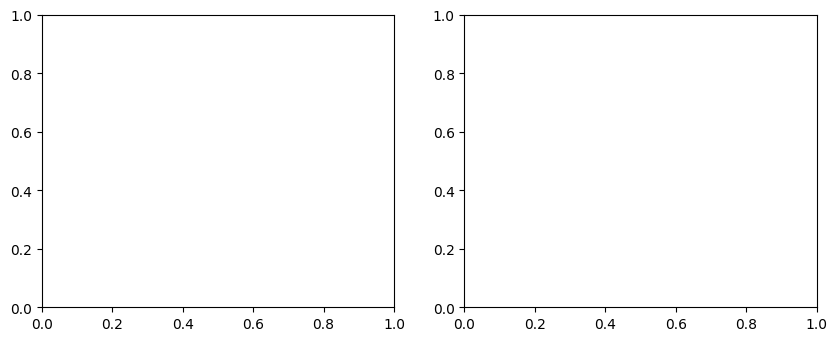

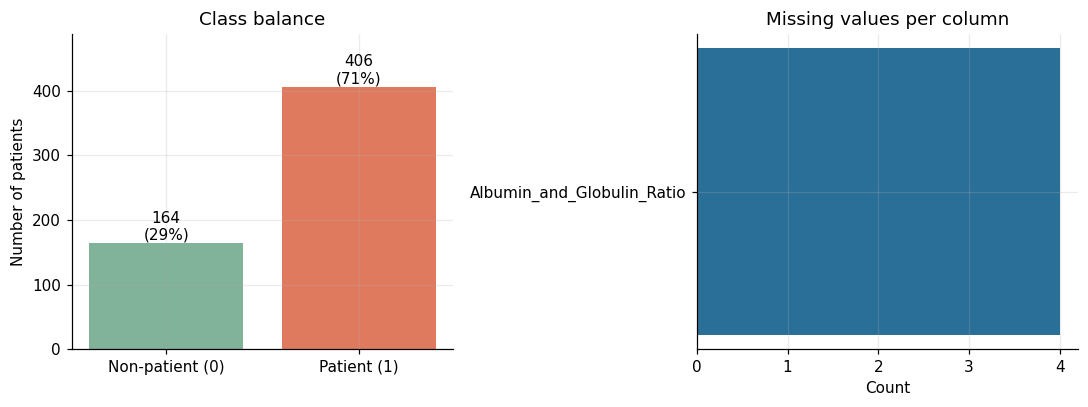

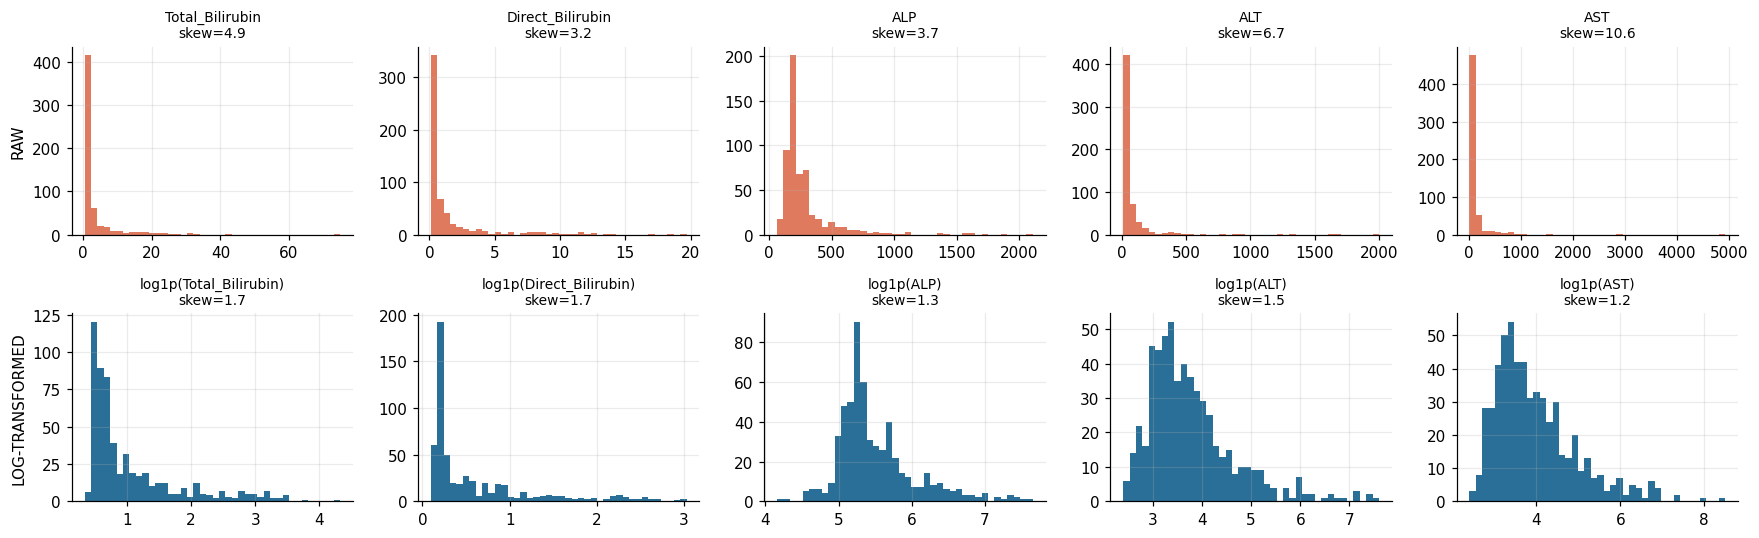

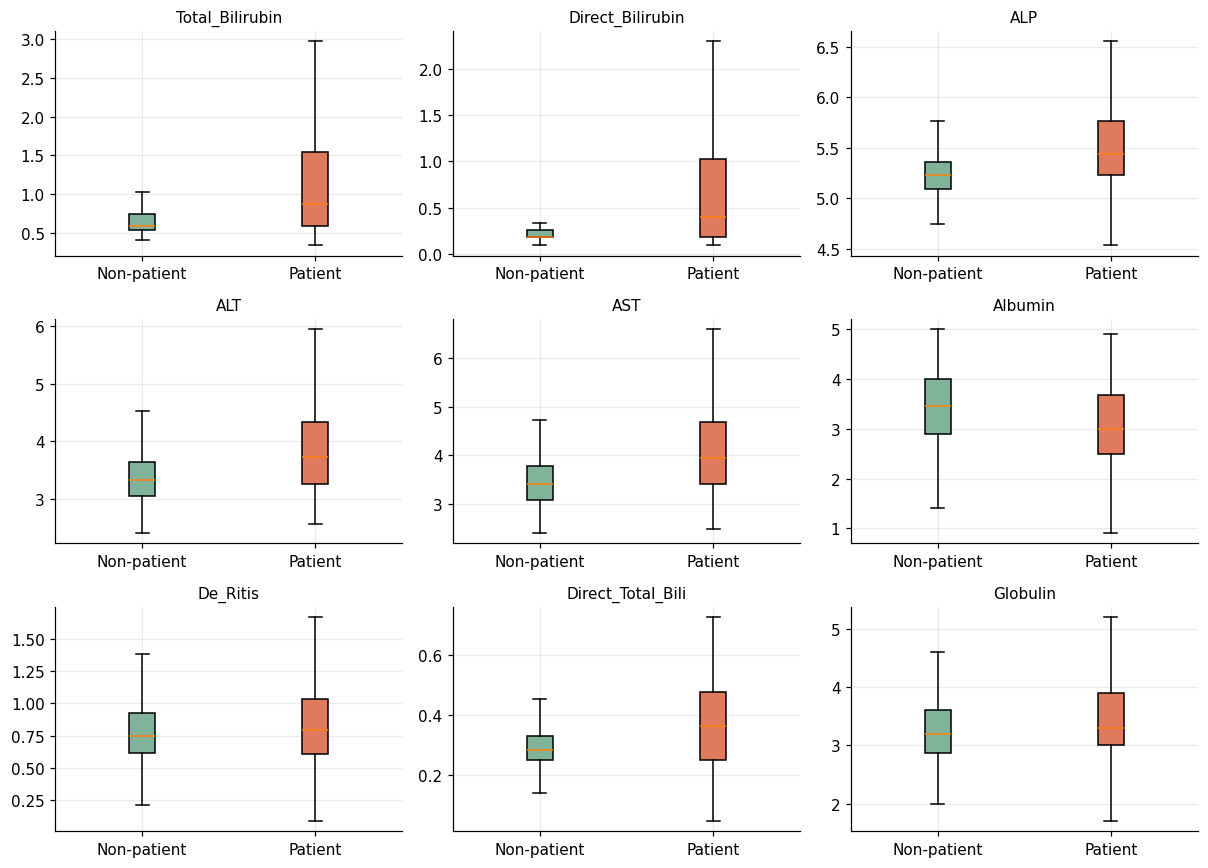

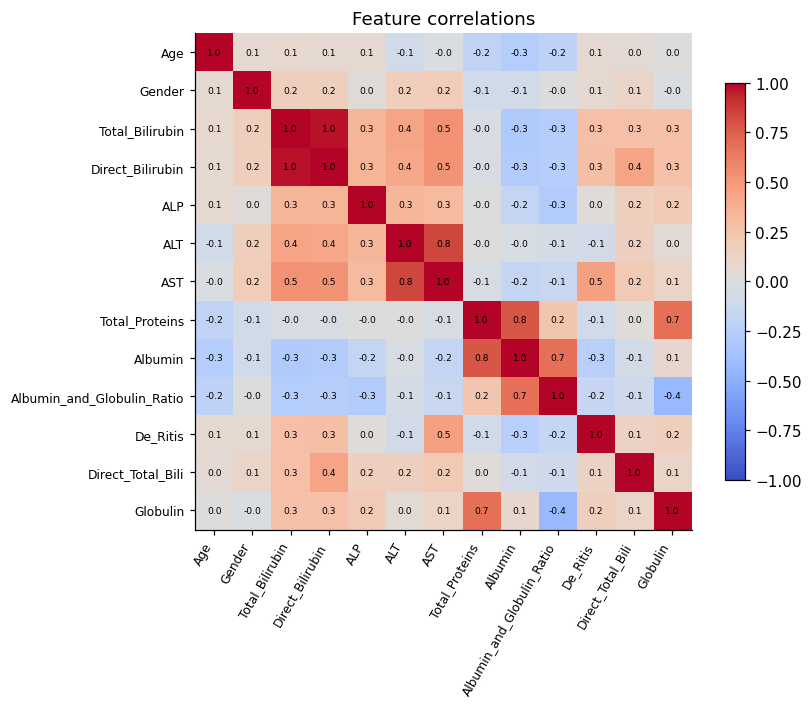

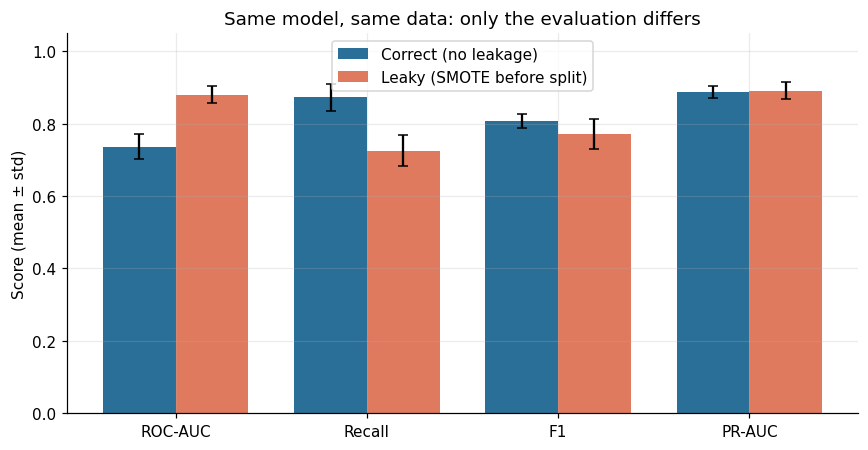

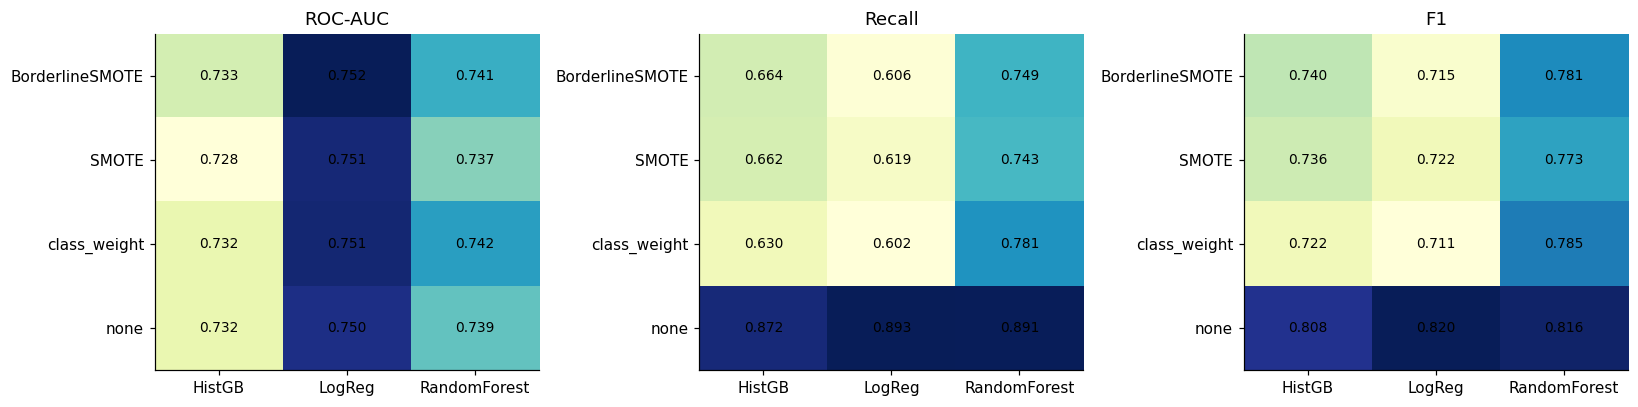

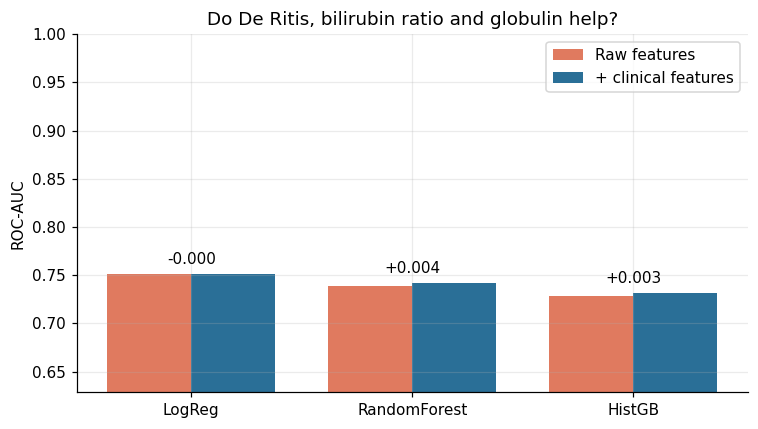

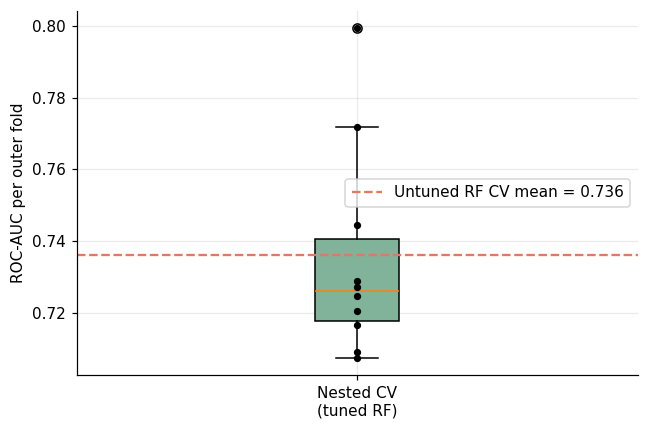

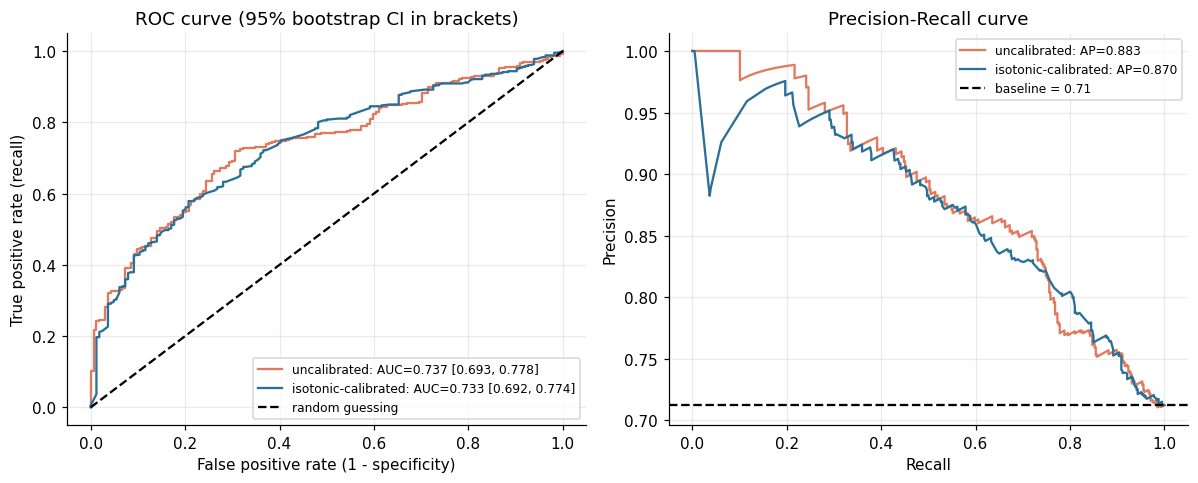

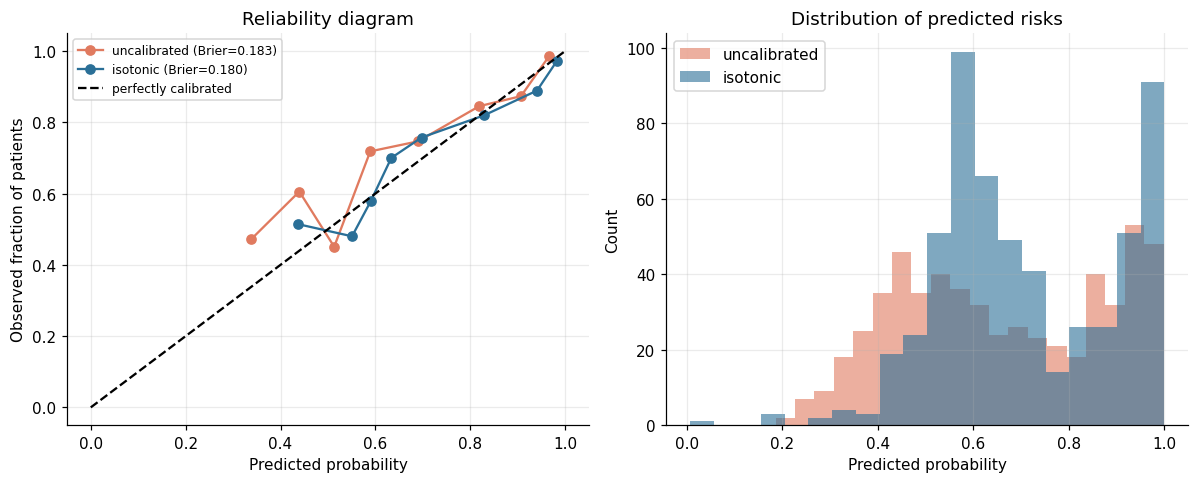

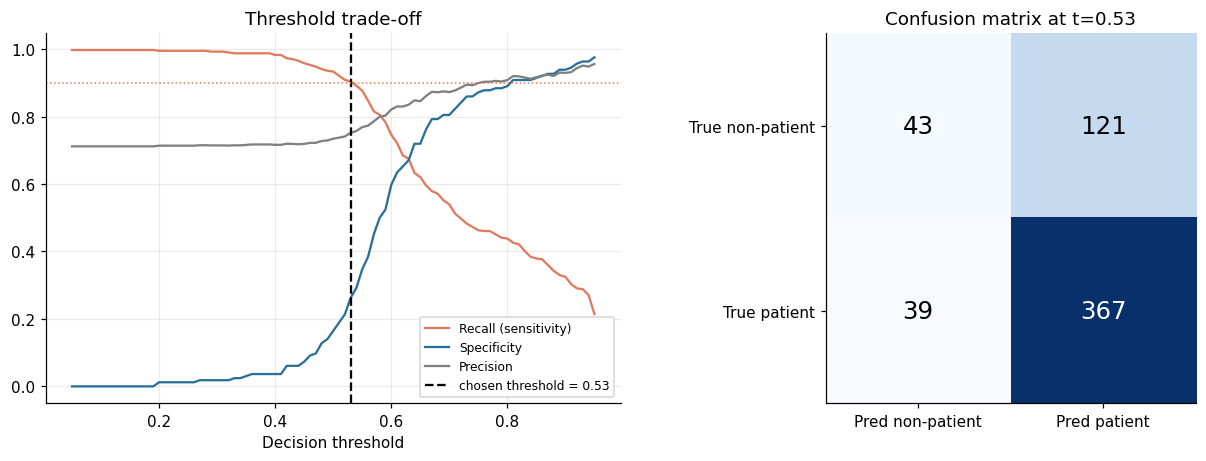

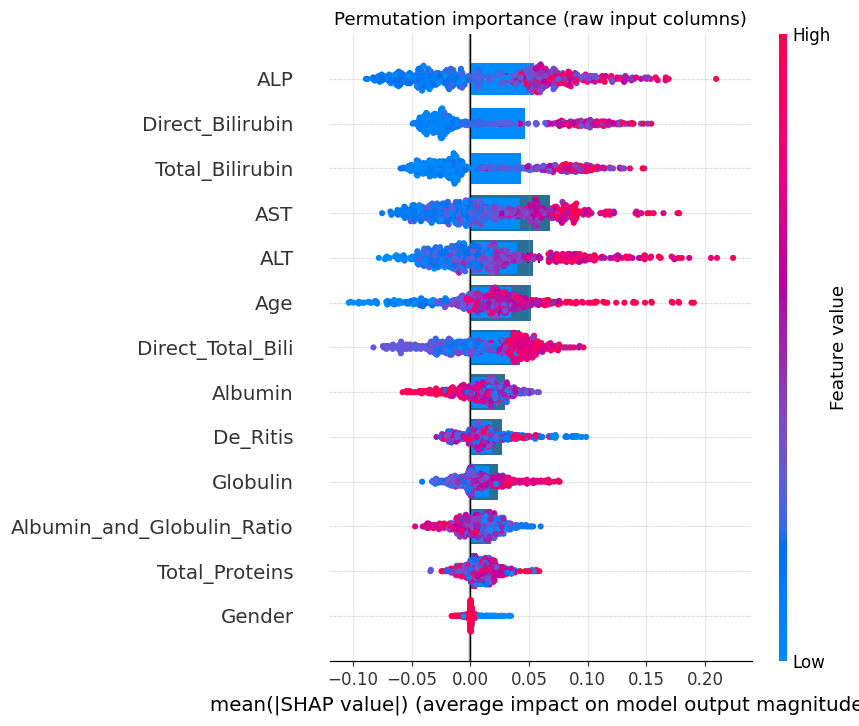

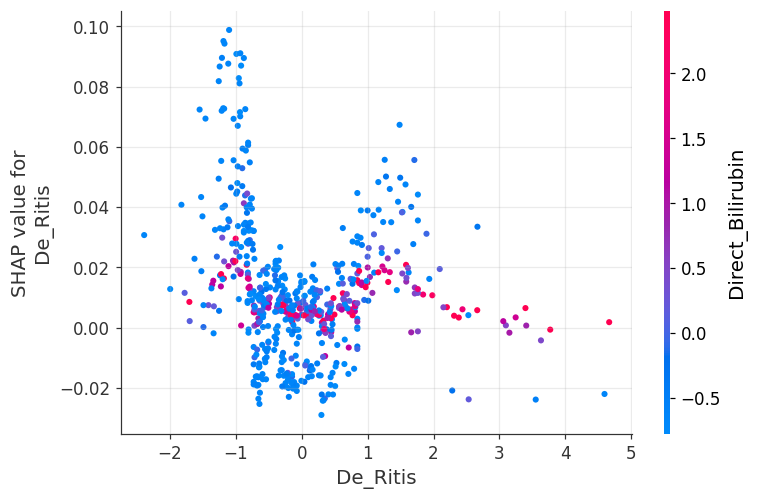

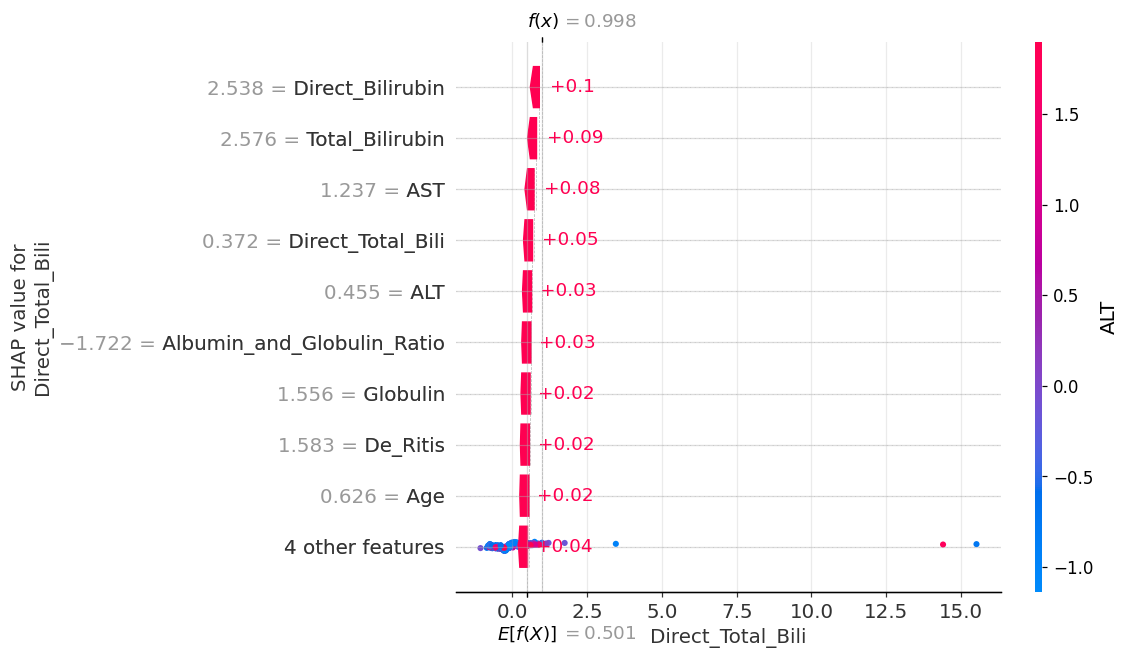

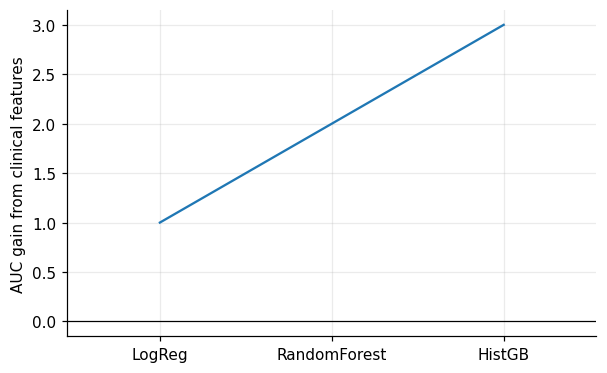

In [57]:
%matplotlib inline
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
import matplotlib.pyplot as plt
plt.plot([1, 2, 3]); plt.show()   # test: a small line should appear

In [58]:
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, confusion_matrix,
                             brier_score_loss)
from sklearn.calibration import calibration_curve

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
C0, C1, C2 = "#2a6f97", "#e07a5f", "#81b29a"   # blue, orange, green

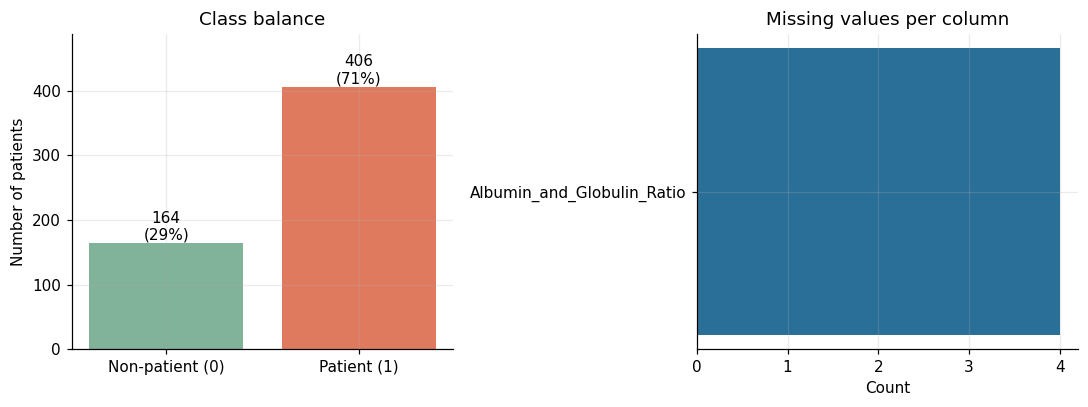

MEANING: 71% of rows are patients. A model that always says 'patient' would already score 71% accuracy, which is why we use recall, F1 and ROC-AUC instead of accuracy.


In [59]:

# %% CELL 1: EDA, class balance and missing values
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
counts = y.value_counts().sort_index()
ax[0].bar(["Non-patient (0)", "Patient (1)"], counts.values, color=[C2, C1])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 5, f"{v}\n({v / len(y):.0%})", ha="center")
ax[0].set_title("Class balance"); ax[0].set_ylabel("Number of patients")
ax[0].set_ylim(0, counts.max() * 1.2)

miss = X.isna().sum()
miss = miss[miss > 0]
if len(miss):
    ax[1].barh(miss.index, miss.values, color=C0)
    ax[1].set_title("Missing values per column"); ax[1].set_xlabel("Count")
else:
    ax[1].text(0.5, 0.5, "No missing values", ha="center"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print(f"MEANING: {counts[1] / len(y):.0%} of rows are patients. A model that always says "
      f"'patient' would already score {counts[1] / len(y):.0%} accuracy, which is why "
      "we use recall, F1 and ROC-AUC instead of accuracy.")


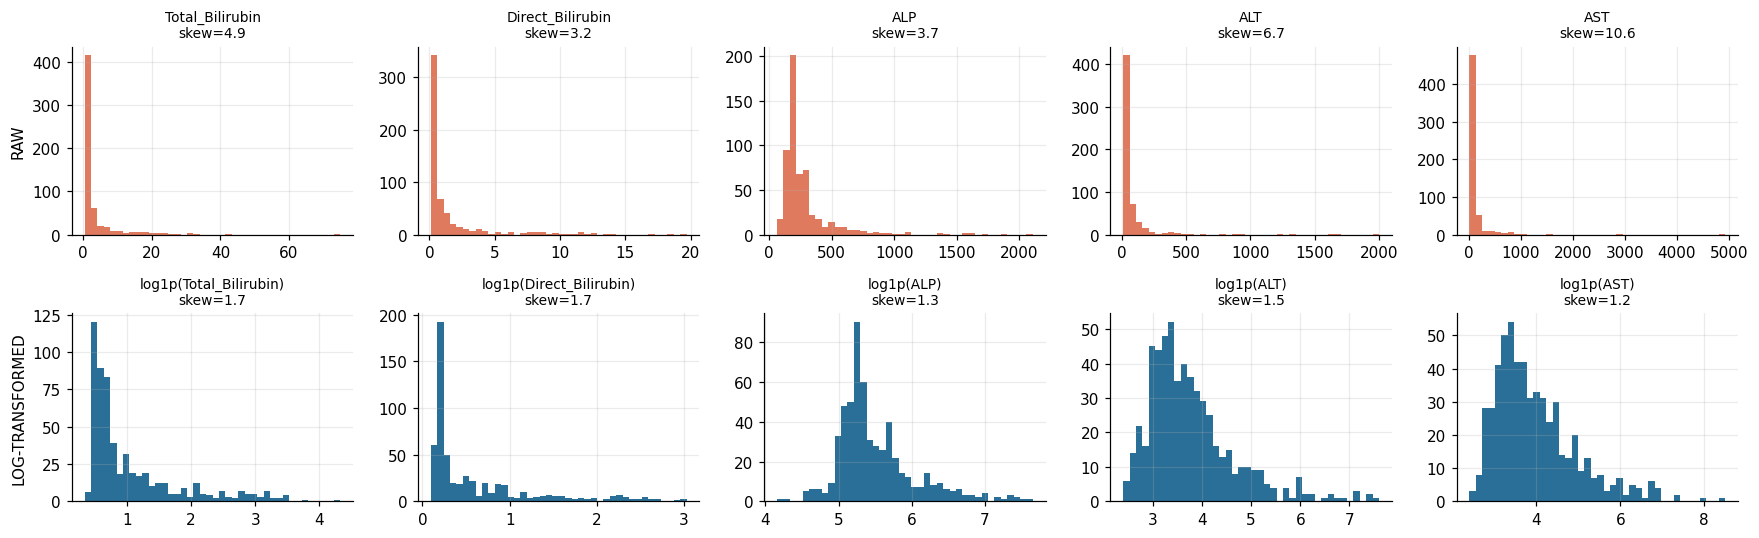

MEANING: raw bilirubin and enzymes have a long right tail (a few huge values). The log transform pulls the tail in (skewness moves toward 0), so no single extreme patient dominates, which especially helps logistic regression.


In [60]:


# %% CELL 2: EDA, why we log-transform (skewness before vs after)
cols = ["Total_Bilirubin", "Direct_Bilirubin", "ALP", "ALT", "AST"]
fig, ax = plt.subplots(2, 5, figsize=(16, 5))
for j, c in enumerate(cols):
    ax[0, j].hist(X[c].dropna(), bins=40, color=C1)
    ax[0, j].set_title(f"{c}\nskew={X[c].skew():.1f}", fontsize=9)
    ax[1, j].hist(Xe[c].dropna(), bins=40, color=C0)
    ax[1, j].set_title(f"log1p({c})\nskew={Xe[c].skew():.1f}", fontsize=9)
ax[0, 0].set_ylabel("RAW"); ax[1, 0].set_ylabel("LOG-TRANSFORMED")
plt.tight_layout(); plt.show()
print("MEANING: raw bilirubin and enzymes have a long right tail (a few huge values). "
      "The log transform pulls the tail in (skewness moves toward 0), so no single "
      "extreme patient dominates, which especially helps logistic regression.")

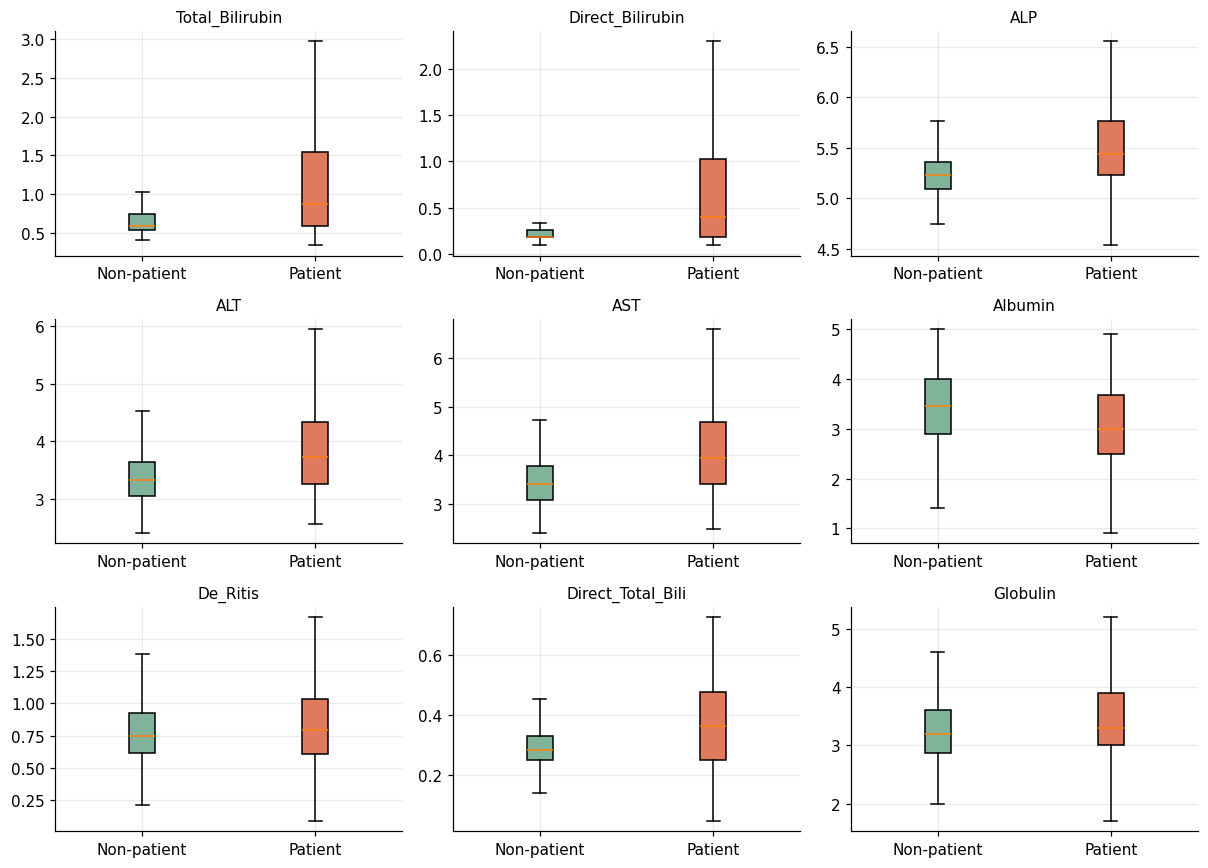

MEANING: features whose boxes barely overlap separate the two groups well, so they carry predictive signal. Heavy overlap means the feature alone cannot tell patients apart, which is why ILPD is a hard dataset (typical AUC is moderate, not near 1).


In [61]:


# %% CELL 3: EDA, patient vs non-patient differences (boxplots)
show = ["Total_Bilirubin", "Direct_Bilirubin", "ALP", "ALT", "AST",
        "Albumin", "De_Ritis", "Direct_Total_Bili", "Globulin"]
fig, ax = plt.subplots(3, 3, figsize=(11, 8))
for a, c in zip(ax.ravel(), show):
    data = [Xe.loc[y == 0, c].dropna(), Xe.loc[y == 1, c].dropna()]
    bp = a.boxplot(data, patch_artist=True, showfliers=False)
    a.set_xticks([1, 2]); a.set_xticklabels(["Non-patient", "Patient"])
    for patch, col in zip(bp["boxes"], [C2, C1]):
        patch.set_facecolor(col)
    a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()
print("MEANING: features whose boxes barely overlap separate the two groups well, so "
      "they carry predictive signal. Heavy overlap means the feature alone cannot "
      "tell patients apart, which is why ILPD is a hard dataset (typical AUC is moderate, not near 1).")

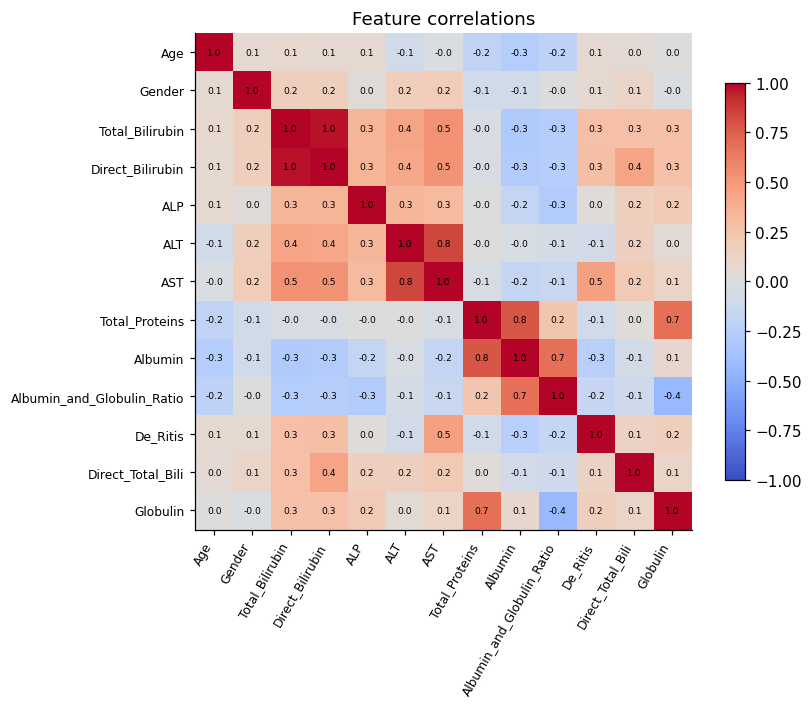

MEANING: strongly correlated pairs (e.g. total and direct bilirubin, ALT and AST) carry overlapping information. This is normal; tree models cope with it, and it explains why SHAP may split credit between such features.


In [62]:

# %% CELL 4: EDA, correlation heatmap
corr = Xe.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("Feature correlations")
plt.tight_layout(); plt.show()
print("MEANING: strongly correlated pairs (e.g. total and direct bilirubin, ALT and AST) "
      "carry overlapping information. This is normal; tree models cope with it, and it "
      "explains why SHAP may split credit between such features.")

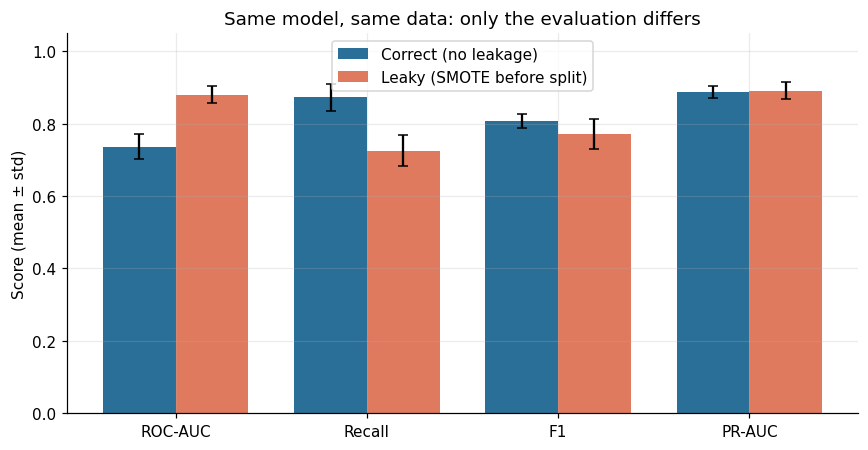

MEANING: ROC-AUC inflated by +0.143 just by doing SMOTE before splitting. The model is identical; only the evaluation is dishonest. This is the central contribution of the project: published ILPD results that skip this care may be optimistic.


In [63]:


# %% CELL 5: RESULT A, leakage experiment
metrics = ["roc_auc", "recall", "f1", "pr_auc"]
x = np.arange(len(metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - w / 2, [clean[m][0] for m in metrics], w, yerr=[clean[m][1] for m in metrics],
       color=C0, label="Correct (no leakage)", capsize=3)
ax.bar(x + w / 2, [leaky[m][0] for m in metrics], w, yerr=[leaky[m][1] for m in metrics],
       color=C1, label="Leaky (SMOTE before split)", capsize=3)
ax.set_xticks(x); ax.set_xticklabels(["ROC-AUC", "Recall", "F1", "PR-AUC"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Score (mean ± std)")
ax.set_title("Same model, same data: only the evaluation differs"); ax.legend()
plt.tight_layout(); plt.show()
gap = leaky["roc_auc"][0] - clean["roc_auc"][0]
print(f"MEANING: ROC-AUC inflated by {gap:+.3f} just by doing SMOTE before splitting. "
      "The model is identical; only the evaluation is dishonest. This is the central "
      "contribution of the project: published ILPD results that skip this care may be optimistic.")

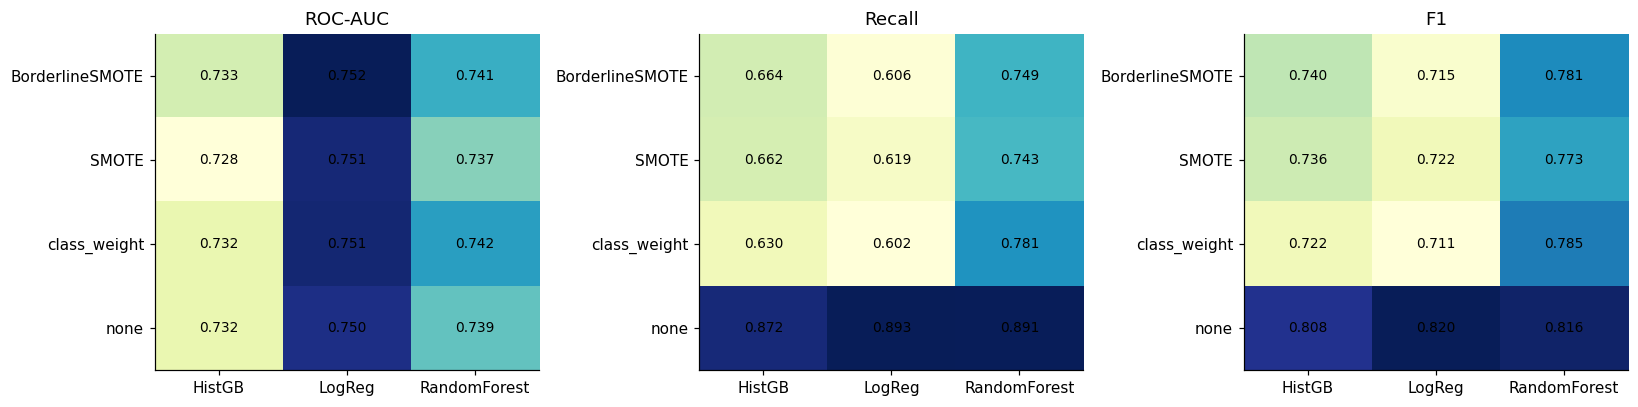

MEANING: best ROC-AUC = 0.752 with BorderlineSMOTE + LogReg. Compare rows to see whether resampling actually helps. If 'none' or 'class_weight' matches SMOTE, report that SMOTE is unnecessary. Differences below ~0.01-0.02 is within noise on 583 rows.


In [64]:


# %% CELL 6: RESULT B, imbalance strategies x models
res = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, metric, title in zip(ax, ["roc_auc", "recall", "f1"], ["ROC-AUC", "Recall", "F1"]):
    pv = res.pivot(index="strategy", columns="model", values=metric)
    im = a.imshow(pv.values, cmap="YlGnBu", aspect="auto")
    a.set_xticks(range(pv.shape[1])); a.set_xticklabels(pv.columns)
    a.set_yticks(range(pv.shape[0])); a.set_yticklabels(pv.index)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            a.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
    a.set_title(title); a.grid(False)
plt.tight_layout(); plt.show()
best_row = res.sort_values("roc_auc", ascending=False).iloc[0]
print(f"MEANING: best ROC-AUC = {best_row.roc_auc:.3f} with {best_row.strategy} + {best_row.model}. "
      "Compare rows to see whether resampling actually helps. If 'none' or 'class_weight' "
      "matches SMOTE, report that SMOTE is unnecessary. Differences below ~0.01-0.02 "
      "is within noise on 583 rows.")


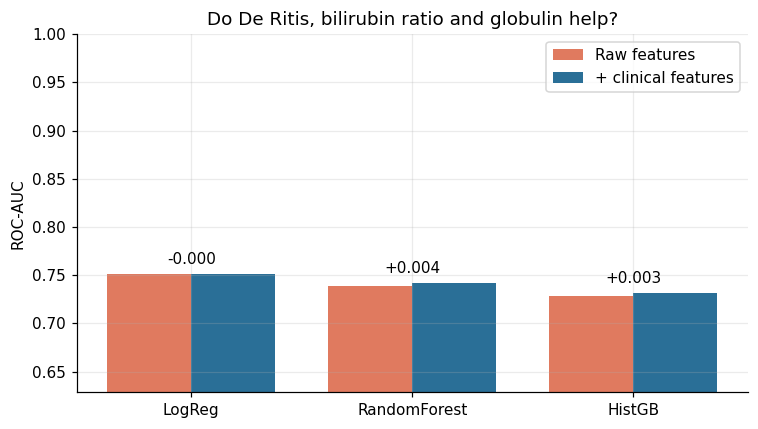

MEANING: positive delta = the engineered features helped that model. Near zero or negative = they added no value on this dataset (still a valid finding, since the information may already be present in the raw columns).


In [65]:

# %% CELL 7: RESULT C, ablation of clinical features
ab = pd.DataFrame(abl)
x = np.arange(len(ab)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w / 2, ab.raw_auc, w, color=C1, label="Raw features")
ax.bar(x + w / 2, ab.eng_auc, w, color=C0, label="+ clinical features")
for i, d in enumerate(ab.delta):
    ax.text(i, max(ab.raw_auc[i], ab.eng_auc[i]) + 0.01, f"{d:+.3f}", ha="center")
ax.set_xticks(x); ax.set_xticklabels(ab.model)
ax.set_ylim(max(0, ab[["raw_auc", "eng_auc"]].min().min() - 0.1), 1)
ax.set_ylabel("ROC-AUC"); ax.set_title("Do De Ritis, bilirubin ratio and globulin help?"); ax.legend()
plt.tight_layout(); plt.show()
print("MEANING: positive delta = the engineered features helped that model. "
      "Near zero or negative = they added no value on this dataset (still a valid finding, "
      "since the information may already be present in the raw columns).")


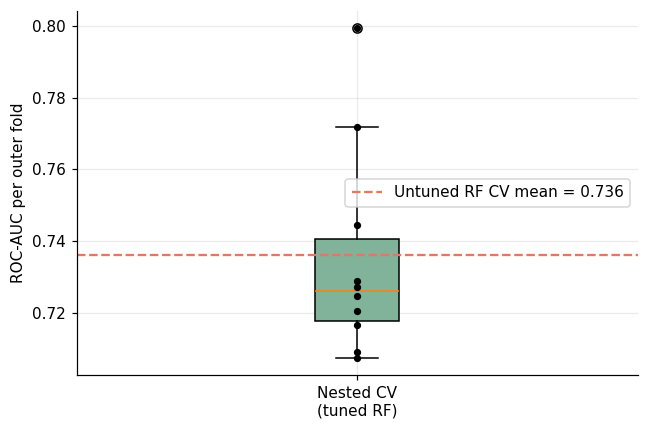

MEANING: nested CV AUC = 0.735 ± 0.028. This is the honest estimate for 'tune hyperparameters, then deploy', because the outer folds never influenced tuning. The spread of the dots shows how unstable results are on a small dataset.


In [66]:

# %% CELL 8: RESULT D, nested CV vs plain CV
ns = nested["test_score"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(ns, patch_artist=True, boxprops=dict(facecolor=C2))
ax.set_xticks([1]); ax.set_xticklabels(["Nested CV\n(tuned RF)"])
ax.scatter(np.ones(len(ns)), ns, color="k", s=14, zorder=3)
ax.axhline(clean["roc_auc"][0], color=C1, ls="--", label=f"Untuned RF CV mean = {clean['roc_auc'][0]:.3f}")
ax.set_ylabel("ROC-AUC per outer fold"); ax.legend()
plt.tight_layout(); plt.show()
print(f"MEANING: nested CV AUC = {ns.mean():.3f} ± {ns.std():.3f}. This is the honest estimate "
      "for 'tune hyperparameters, then deploy', because the outer folds never influenced tuning. "
      "The spread of the dots shows how unstable results are on a small dataset.")

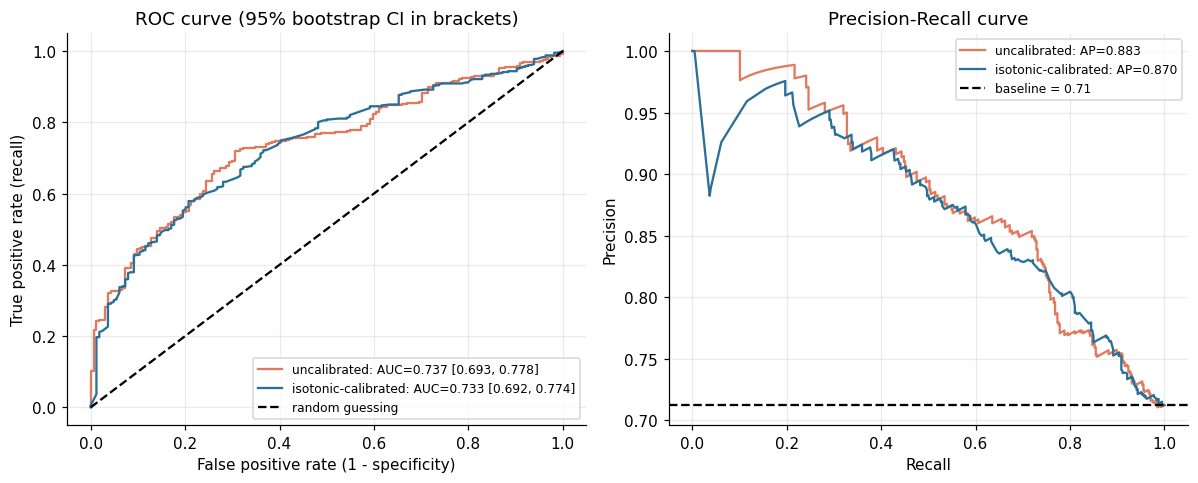

MEANING: ROC: the further the curve bows toward the top-left, the better the ranking of patients above non-patients. The CI shows the uncertainty from having only 583 rows. PR curve: must stay above the baseline (the patient prevalence) to beat guessing.


In [67]:

# %% CELL 9: RESULT E1, ROC and Precision-Recall curves with bootstrap CI
rng = np.random.default_rng(0)
yv = y.values


def boot_ci(p, fn, n=1000):
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(yv), len(yv))
        if yv[idx].min() == yv[idx].max():
            continue
        vals.append(fn(yv[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])


fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p, col in [("uncalibrated", p_raw, C1), ("isotonic-calibrated", p_cal, C0)]:
    fpr, tpr, _ = roc_curve(yv, p)
    lo, hi = boot_ci(p, roc_auc_score)
    ax[0].plot(fpr, tpr, color=col, label=f"{name}: AUC={roc_auc_score(yv, p):.3f} [{lo:.3f}, {hi:.3f}]")
    pr, rc, _ = precision_recall_curve(yv, p)
    ax[1].plot(rc, pr, color=col, label=f"{name}: AP={average_precision_score(yv, p):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", label="random guessing")
ax[0].set_xlabel("False positive rate (1 - specificity)"); ax[0].set_ylabel("True positive rate (recall)")
ax[0].set_title("ROC curve (95% bootstrap CI in brackets)"); ax[0].legend(fontsize=8)
ax[1].axhline(yv.mean(), color="k", ls="--", label=f"baseline = {yv.mean():.2f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall curve")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("MEANING: ROC: the further the curve bows toward the top-left, the better the ranking "
      "of patients above non-patients. The CI shows the uncertainty from having only 583 rows. "
      "PR curve: must stay above the baseline (the patient prevalence) to beat guessing.")


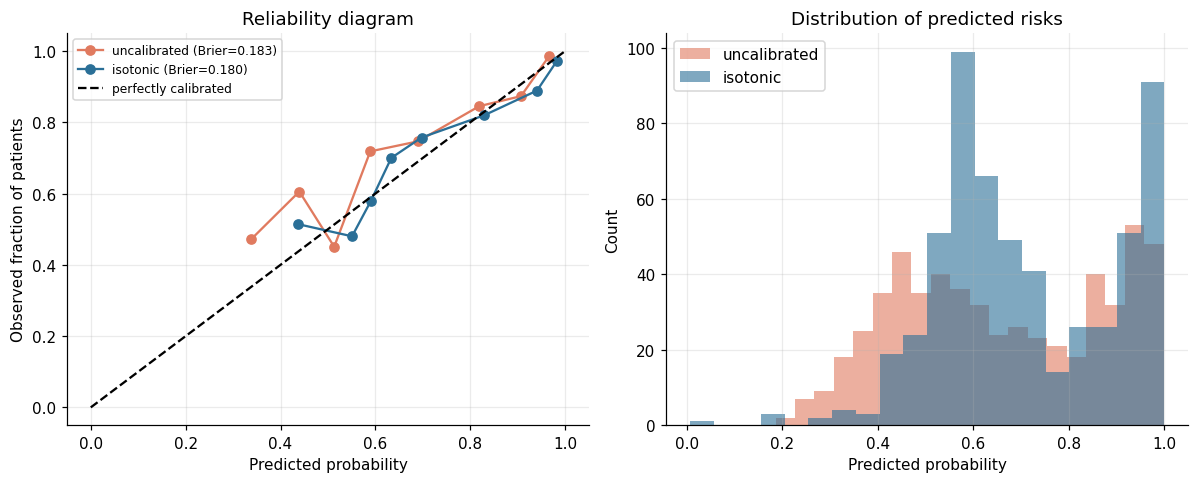

MEANING: points on the diagonal mean 'when the model says 70%, about 70% truly are patients'. Brier score went 0.1825 -> 0.1804 after calibration (improved). Calibrated risks can be shown to a clinician as real probabilities.


In [68]:

# %% CELL 10: RESULT E2, calibration
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p, col in [("uncalibrated", p_raw, C1), ("isotonic", p_cal, C0)]:
    fp, mp = calibration_curve(yv, p, n_bins=8, strategy="quantile")
    ax[0].plot(mp, fp, marker="o", color=col, label=f"{name} (Brier={brier_score_loss(yv, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
ax[0].set_xlabel("Predicted probability"); ax[0].set_ylabel("Observed fraction of patients")
ax[0].set_title("Reliability diagram"); ax[0].legend(fontsize=8)
ax[1].hist(p_raw, bins=20, alpha=0.6, color=C1, label="uncalibrated")
ax[1].hist(p_cal, bins=20, alpha=0.6, color=C0, label="isotonic")
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Count"); ax[1].legend()
ax[1].set_title("Distribution of predicted risks")
plt.tight_layout(); plt.show()
b0, b1 = brier_score_loss(yv, p_raw), brier_score_loss(yv, p_cal)
print(f"MEANING: points on the diagonal mean 'when the model says 70%, about 70% truly are patients'. "
      f"Brier score went {b0:.4f} -> {b1:.4f} after calibration "
      f"({'improved' if b1 < b0 else 'did not improve'}). Calibrated risks can be shown to a clinician as real probabilities.")

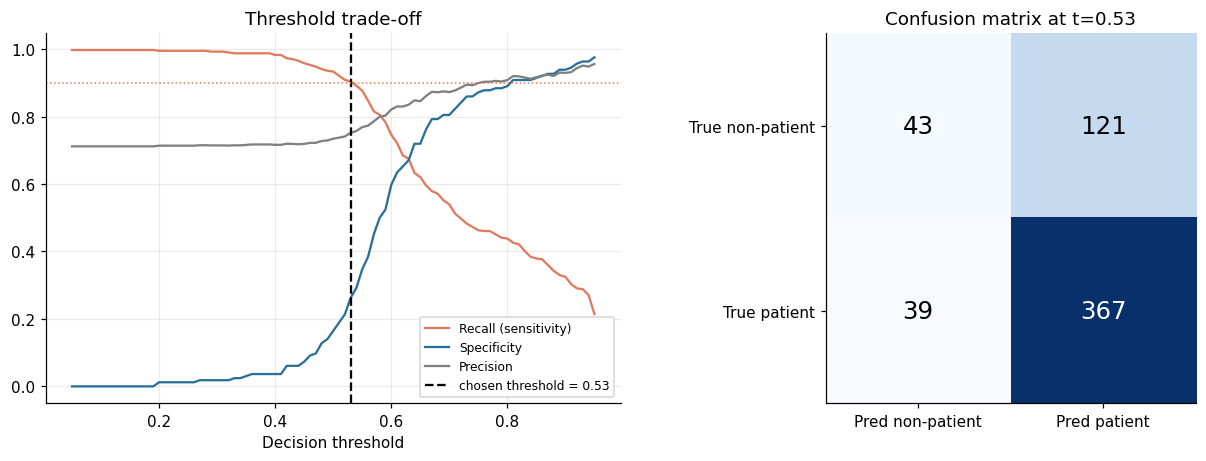

MEANING: lowering the threshold raises recall but lowers specificity. At t=0.53: 367 patients caught, 39 missed (recall 0.90); 121 healthy people flagged (specificity 0.26). A missed patient is usually costlier than a false alarm in screening, which justifies a low threshold.


In [69]:


# %% CELL 11: RESULT E3, threshold trade-off and confusion matrix
ths = np.linspace(0.05, 0.95, 91)
rec, spe, pre = [], [], []
for t in ths:
    pred = p_cal >= t
    tp = (pred & (yv == 1)).sum(); fn = ((~pred) & (yv == 1)).sum()
    tn = ((~pred) & (yv == 0)).sum(); fp_ = (pred & (yv == 0)).sum()
    rec.append(tp / (tp + fn)); spe.append(tn / (tn + fp_)); pre.append(tp / max(tp + fp_, 1))
chosen = best[0] if best else 0.5
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].plot(ths, rec, color=C1, label="Recall (sensitivity)")
ax[0].plot(ths, spe, color=C0, label="Specificity")
ax[0].plot(ths, pre, color="gray", label="Precision")
ax[0].axvline(chosen, color="k", ls="--", label=f"chosen threshold = {chosen:.2f}")
ax[0].axhline(0.90, color=C1, ls=":", lw=1)
ax[0].set_xlabel("Decision threshold"); ax[0].set_title("Threshold trade-off"); ax[0].legend(fontsize=8)
cm = confusion_matrix(yv, (p_cal >= chosen).astype(int))
ax[1].imshow(cm, cmap="Blues"); ax[1].grid(False)
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Pred non-patient", "Pred patient"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["True non-patient", "True patient"])
ax[1].set_title(f"Confusion matrix at t={chosen:.2f}")
plt.tight_layout(); plt.show()
tn_, fp_, fn_, tp_ = cm.ravel()
print(f"MEANING: lowering the threshold raises recall but lowers specificity. At t={chosen:.2f}: "
      f"{tp_} patients caught, {fn_} missed (recall {tp_ / (tp_ + fn_):.2f}); "
      f"{fp_} healthy people flagged (specificity {tn_ / (tn_ + fp_):.2f}). "
      "A missed patient is usually costlier than a false alarm in screening, which justifies a low threshold.")


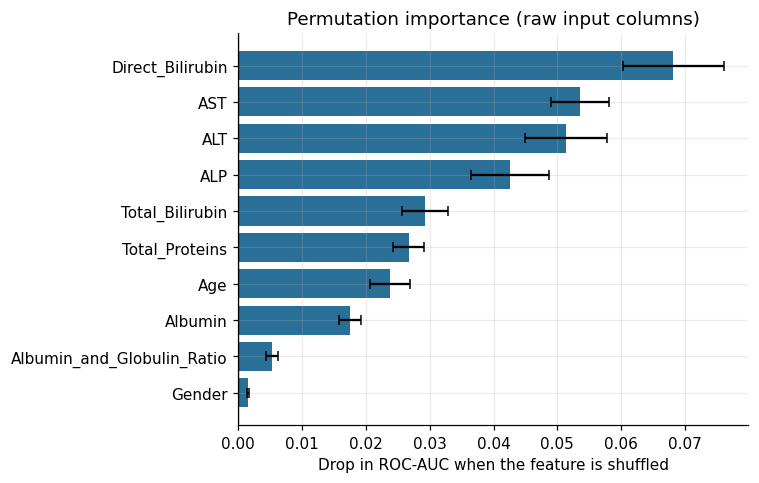

MEANING: the longer the bar, the more the model depends on that column. Top 3: ['Direct_Bilirubin', 'AST', 'ALT']. Bars near zero (or with error bars crossing zero) are features the model barely uses. Note: this is measured on training data of the final model, so treat it as 'what the model uses', not 'how well it generalizes'.


In [70]:

# %% CELL 12: RESULT F1, permutation importance
imp = pd.DataFrame({"feature": X.columns, "mean": pi.importances_mean,
                    "std": pi.importances_std}).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.feature, imp["mean"], xerr=imp["std"], color=C0, capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance (raw input columns)")
plt.tight_layout(); plt.show()
top = imp.sort_values("mean", ascending=False).head(3).feature.tolist()
print(f"MEANING: the longer the bar, the more the model depends on that column. Top 3: {top}. "
      "Bars near zero (or with error bars crossing zero) are features the model barely uses. "
      "Note: this is measured on training data of the final model, so treat it as 'what the model uses', not 'how well it generalizes'.")


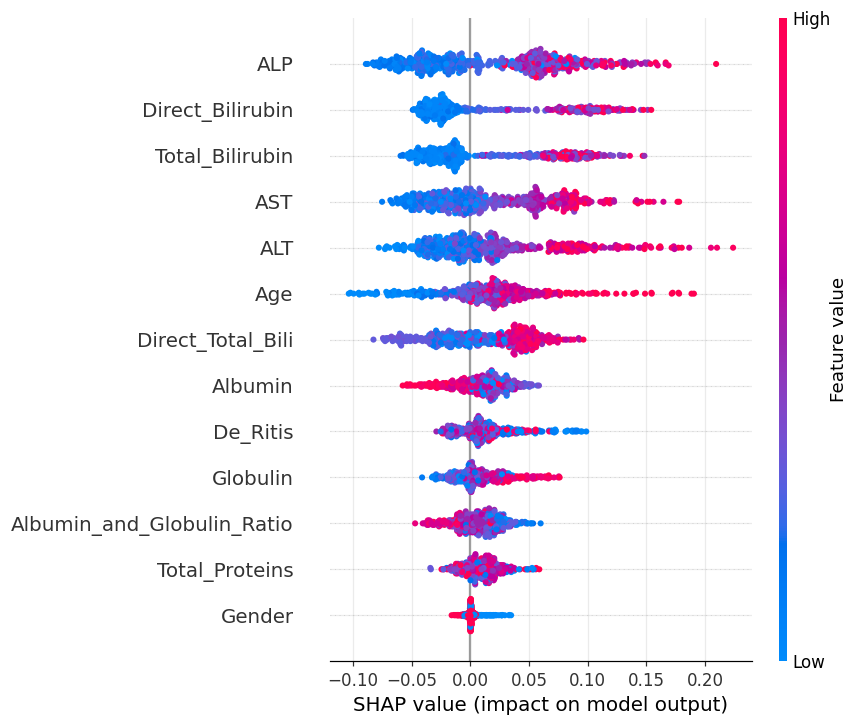

MEANING (summary plot): each dot is one patient. Position left/right = pushes the prediction toward non-patient/patient. Colour = the feature value (red high, blue low). Example check: if high bilirubin is red on the right, the model agrees with medicine.


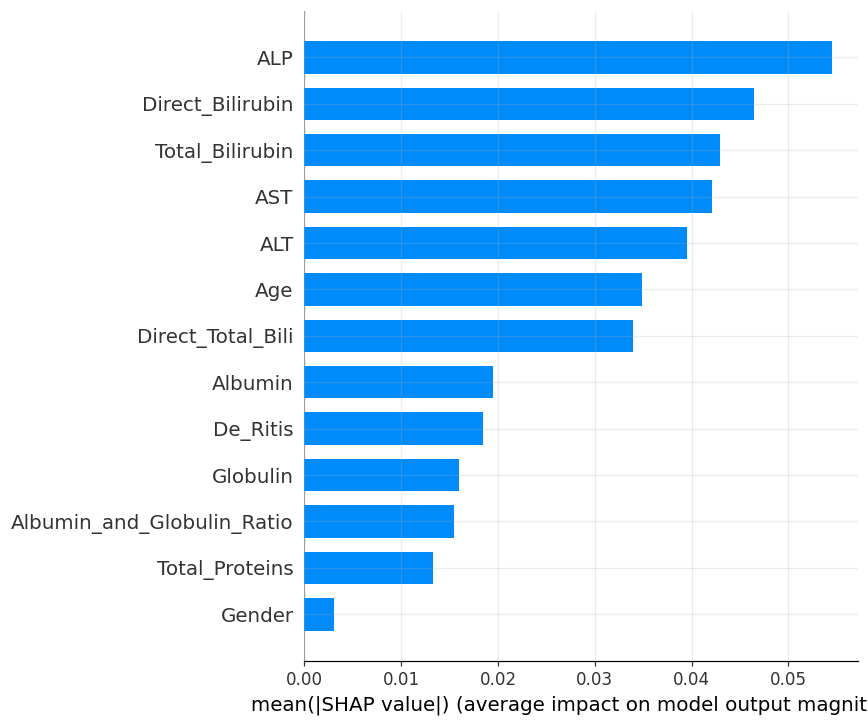

MEANING (bar plot): average absolute impact of each feature, i.e. global importance on the model's own scale.


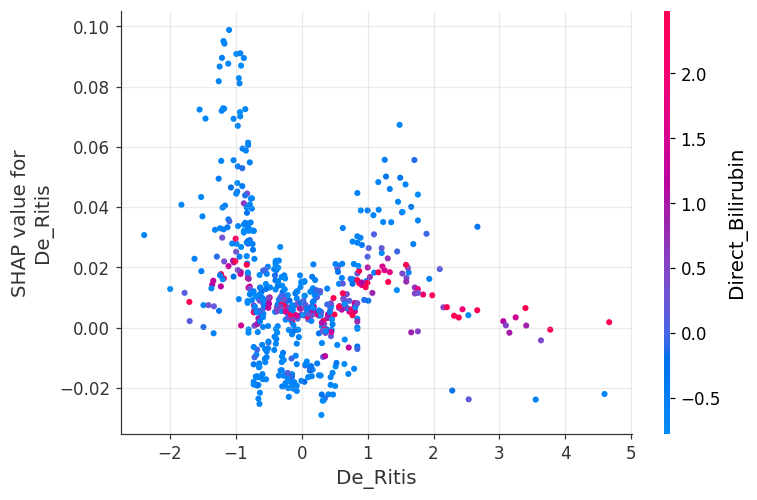

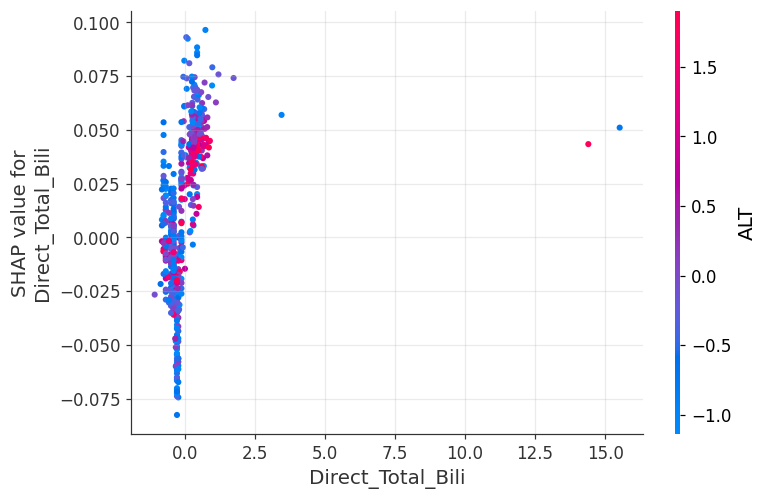

MEANING (dependence plots): how the effect of one feature changes with its value. Look for the direction and for thresholds where the effect flips; compare with clinical knowledge.


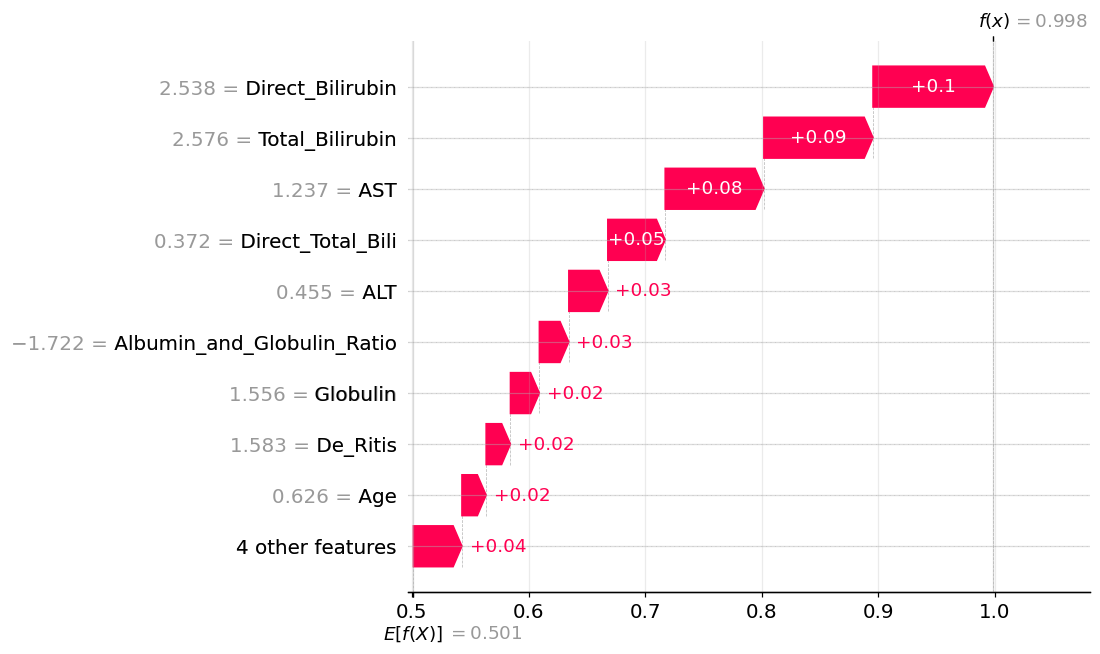

MEANING (waterfall, patient index 46): starts at the average prediction and shows how each feature pushes this one patient's risk up (red) or down (blue). This is the per-patient explanation a doctor would want. Features are standardized, so values are in z-scores.


In [71]:

# %% CELL 13: RESULT F2, SHAP (global + dependence + one patient)
import shap
shap.summary_plot(sv, Xt, show=True)
print("MEANING (summary plot): each dot is one patient. Position left/right = pushes the "
      "prediction toward non-patient/patient. Colour = the feature value (red high, blue low). "
      "Example check: if high bilirubin is red on the right, the model agrees with medicine.")

shap.summary_plot(sv, Xt, plot_type="bar", show=True)
print("MEANING (bar plot): average absolute impact of each feature, i.e. global importance on the model's own scale.")

for feat in ["De_Ritis", "Direct_Total_Bili"]:
    if feat in Xt.columns:
        shap.dependence_plot(feat, sv, Xt, show=True)
print("MEANING (dependence plots): how the effect of one feature changes with its value. "
      "Look for the direction and for thresholds where the effect flips; compare with clinical knowledge.")

i = int(np.argmax(final.named_steps["clf"].predict_proba(Xt)[:, 1]))
ev = shap.TreeExplainer(final.named_steps["clf"]).expected_value
ev = ev[1] if np.ndim(ev) else ev
shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=ev,
                                      data=Xt.iloc[i].values, feature_names=list(Xt.columns)),
                     show=True)
print(f"MEANING (waterfall, patient index {i}): starts at the average prediction and shows how each "
      "feature pushes this one patient's risk up (red) or down (blue). This is the per-patient "
      "explanation a doctor would want. Features are standardized, so values are in z-scores.")

Paired comparison on identical CV splits (raw vs + clinical features), ROC-AUC per fold:
  LogReg        mean diff = -0.0004   Wilcoxon p = 0.568
  RandomForest  mean diff = +0.0036   Wilcoxon p = 0.210
  HistGB        mean diff = +0.0032   Wilcoxon p = 0.139


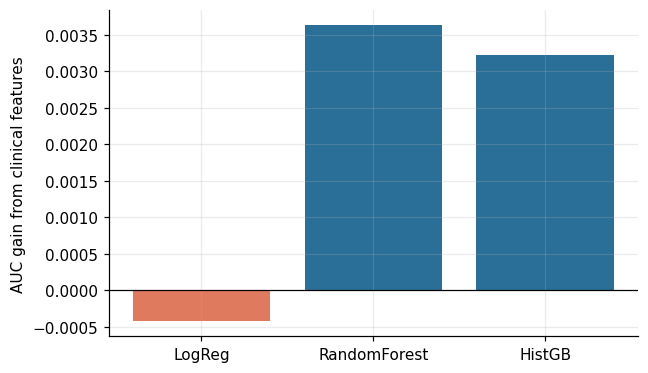

MEANING: p < 0.05 suggests the gain is unlikely to be pure chance. CAUTION: CV folds share training data, so they are not independent and these p-values are optimistic. Treat them as a guide, and give more weight to effect size (mean diff) and the bootstrap CI in Cell 9. A tiny gain with p < 0.05 is statistically real but may be clinically unimportant.


In [72]:

# %% CELL 14: SIGNIFICANCE, is the improvement real or noise?
from scipy.stats import wilcoxon
from sklearn.model_selection import cross_validate
from sklearn.base import clone

print("Paired comparison on identical CV splits (raw vs + clinical features), ROC-AUC per fold:")
out = []
for mname, m in models("balanced").items():
    a = cross_validate(make_pipe(clone(m), engineered=False), X, y, cv=CV, scoring="roc_auc")["test_score"]
    b = cross_validate(make_pipe(clone(m), engineered=True), X, y, cv=CV, scoring="roc_auc")["test_score"]
    d = b - a
    try:
        p_val = wilcoxon(b, a).pvalue
    except ValueError:        # all differences are zero
        p_val = 1.0
    out.append({"model": mname, "mean_diff": d.mean(), "p_value": p_val})
    print(f"  {mname:13s} mean diff = {d.mean():+.4f}   Wilcoxon p = {p_val:.3f}")
sig = pd.DataFrame(out)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(sig.model, sig.mean_diff, color=[C0 if v > 0 else C1 for v in sig.mean_diff])
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("AUC gain from clinical features")
plt.tight_layout(); plt.show()
print("MEANING: p < 0.05 suggests the gain is unlikely to be pure chance. CAUTION: CV folds share "
      "training data, so they are not independent and these p-values are optimistic. Treat them as "
      "a guide, and give more weight to effect size (mean diff) and the bootstrap CI in Cell 9. "
      "A tiny gain with p < 0.05 is statistically real but may be clinically unimportant.")

In [73]:

# %% CELL 15: one-screen project summary
print("=" * 60)
print("PROJECT SUMMARY (auto-generated from your results)")
print("=" * 60)
print(f"Data: {len(y)} patients, {y.mean():.0%} positive (liver patient).")
print(f"Leakage check: leaky AUC {leaky['roc_auc'][0]:.3f} vs correct {clean['roc_auc'][0]:.3f} "
      f"(inflation {leaky['roc_auc'][0] - clean['roc_auc'][0]:+.3f}).")
print(f"Best imbalance setup: {best_row.strategy} + {best_row.model}, AUC {best_row.roc_auc:.3f}.")
print(f"Nested CV (tuned RF): {ns.mean():.3f} ± {ns.std():.3f}  <- honest headline number.")
print(f"Calibration: Brier {b0:.4f} -> {b1:.4f}.")
print(f"Screening threshold {chosen:.2f}: recall {tp_ / (tp_ + fn_):.2f}, specificity {tn_ / (tn_ + fp_):.2f}.")
print("Top permutation-importance features:", top)
print("Limitations to state: small single-source dataset, no external validation, binary label only, "
      "screening aid not a diagnosis.")

PROJECT SUMMARY (auto-generated from your results)
Data: 570 patients, 71% positive (liver patient).
Leakage check: leaky AUC 0.880 vs correct 0.736 (inflation +0.143).
Best imbalance setup: BorderlineSMOTE + LogReg, AUC 0.752.
Nested CV (tuned RF): 0.735 ± 0.028  <- honest headline number.
Calibration: Brier 0.1825 -> 0.1804.
Screening threshold 0.53: recall 0.90, specificity 0.26.
Top permutation-importance features: ['Direct_Bilirubin', 'AST', 'ALT']
Limitations to state: small single-source dataset, no external validation, binary label only, screening aid not a diagnosis.
